In [23]:

import os
import re
import html
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")


Libraries imported successfully!


In [24]:

from google.colab import files

uploaded = files.upload()
zip_files = [name for name in uploaded if name.lower().endswith(".zip")]

if not zip_files:
    raise ValueError("Please upload the ZIP file containing Fake.csv and True.csv.")

zip_path = zip_files[0]
extract_path = "/content/fake_news_data"
os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extracted files:", os.listdir(extract_path))


Saving Fake and Real News Dataset.zip to Fake and Real News Dataset (1).zip
Extracted files: ['Fake.csv', 'True.csv']


In [25]:

fake_path = os.path.join(extract_path, "Fake.csv")
real_path = os.path.join(extract_path, "True.csv")

fake_df = pd.read_csv(fake_path)
real_df = pd.read_csv(real_path)

print("Fake news rows and columns:", fake_df.shape)
print("Real news rows and columns:", real_df.shape)

print("\nFake news columns:")
print(fake_df.columns.tolist())

print("\nReal news columns:")
print(real_df.columns.tolist())

display(fake_df.head(3))
display(real_df.head(3))


Fake news rows and columns: (23481, 4)
Real news rows and columns: (21417, 4)

Fake news columns:
['title', 'text', 'subject', 'date']

Real news columns:
['title', 'text', 'subject', 'date']


,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"


,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"


In [26]:

fake_df["label"] = 1
real_df["label"] = 0

news_df = pd.concat([fake_df, real_df], ignore_index=True)

# Shuffle rows reproducibly
news_df = news_df.sample(frac=1, random_state=42).reset_index(drop=True)

print("Combined dataset shape:", news_df.shape)
print("\nLabel counts:")
print(news_df["label"].value_counts())

display(news_df.head())


Combined dataset shape: (44898, 5)

Label counts:
label
1    23481
0    21417
Name: count, dtype: int64


,title,text,subject,date,label
0,Ben Stein Calls Out 9th Circuit Court: Committ...,"21st Century Wire says Ben Stein, reputable pr...",US_News,"February 13, 2017",1
1,Trump drops Steve Bannon from National Securit...,WASHINGTON (Reuters) - U.S. President Donald T...,politicsNews,"April 5, 2017",0
2,Puerto Rico expects U.S. to lift Jones Act shi...,(Reuters) - Puerto Rico Governor Ricardo Rosse...,politicsNews,"September 27, 2017",0
3,OOPS: Trump Just Accidentally Confirmed He Le...,"On Monday, Donald Trump once again embarrassed...",News,"May 22, 2017",1
4,Donald Trump heads for Scotland to reopen a go...,"GLASGOW, Scotland (Reuters) - Most U.S. presid...",politicsNews,"June 24, 2016",0


In [27]:

print("Missing values:")
print(news_df[["title", "text", "label"]].isnull().sum())

print("\nExact duplicate rows:", news_df.duplicated().sum())

print("\nDuplicate article texts:", news_df["text"].duplicated().sum())


Missing values:
title    0
text     0
label    0
dtype: int64

Exact duplicate rows: 209

Duplicate article texts: 6252


In [28]:

# Remove rows with missing title or text
news_df = news_df.dropna(subset=["title", "text"]).copy()

# Remove empty title/text rows
news_df["title"] = news_df["title"].astype(str).str.strip()
news_df["text"] = news_df["text"].astype(str).str.strip()

news_df = news_df[
    (news_df["title"] != "") &
    (news_df["text"] != "")
].copy()

# Remove exact duplicate rows
news_df = news_df.drop_duplicates().reset_index(drop=True)

# Combine title and article body
news_df["content"] = news_df["title"] + " " + news_df["text"]

print("Rows after cleaning:", len(news_df))
print("\nLabel distribution:")
print(news_df["label"].value_counts())

display(news_df[["title", "text", "label", "content"]].head(2))


Rows after cleaning: 44056

Label distribution:
label
1    22846
0    21210
Name: count, dtype: int64


,title,text,label,content
0,Ben Stein Calls Out 9th Circuit Court: Committ...,"21st Century Wire says Ben Stein, reputable pr...",1,Ben Stein Calls Out 9th Circuit Court: Committ...
1,Trump drops Steve Bannon from National Securit...,WASHINGTON (Reuters) - U.S. President Donald T...,0,Trump drops Steve Bannon from National Securit...


In [29]:

import nltk

nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

print("NLTK resources downloaded!")


NLTK resources downloaded!


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [30]:

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = html.unescape(str(text))
    text = text.lower()
    text = re.sub(r"<[^>]+>", " ", text)       # Remove HTML tags
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)  # Remove URLs
    text = re.sub(r"[^a-z\s]", " ", text)      # Keep English letters
    words = text.split()

    cleaned_words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word not in stop_words and len(word) > 1
    ]

    return " ".join(cleaned_words)

news_df["clean_content"] = news_df["content"].apply(clean_text)

display(news_df[["content", "clean_content", "label"]].head(3))


,content,clean_content,label
0,Ben Stein Calls Out 9th Circuit Court: Committ...,ben stein call th circuit court committed coup...,1
1,Trump drops Steve Bannon from National Securit...,trump drop steve bannon national security coun...,0
2,Puerto Rico expects U.S. to lift Jones Act shi...,puerto rico expects lift jones act shipping re...,0


In [31]:

X = news_df["clean_content"]
y = news_df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training articles:", len(X_train))
print("Testing articles:", len(X_test))

print("\nTraining label proportions:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting label proportions:")
print(y_test.value_counts(normalize=True).round(3))


Training articles: 35244
Testing articles: 8812

Training label proportions:
label
1    0.519
0    0.481
Name: proportion, dtype: float64

Testing label proportions:
label
1    0.519
0    0.481
Name: proportion, dtype: float64


In [32]:

tfidf = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training feature matrix:", X_train_tfidf.shape)
print("Testing feature matrix:", X_test_tfidf.shape)


Training feature matrix: (35244, 50000)
Testing feature matrix: (8812, 50000)


In [33]:

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

print("Training Logistic Regression...")
logistic_model.fit(X_train_tfidf, y_train)

y_pred_lr = logistic_model.predict(X_test_tfidf)

print("\nLogistic Regression Results")
print("Accuracy:", round(accuracy_score(y_test, y_pred_lr), 4))
print("Precision:", round(precision_score(y_test, y_pred_lr), 4))
print("Recall:", round(recall_score(y_test, y_pred_lr), 4))
print("F1-score:", round(f1_score(y_test, y_pred_lr), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_lr,
    target_names=["Real", "Fake"]
))


Training Logistic Regression...

Logistic Regression Results
Accuracy: 0.9918
Precision: 0.9939
Recall: 0.9904
F1-score: 0.9921

Classification Report:
              precision    recall  f1-score   support

        Real       0.99      0.99      0.99      4242
        Fake       0.99      0.99      0.99      4570

    accuracy                           0.99      8812
   macro avg       0.99      0.99      0.99      8812
weighted avg       0.99      0.99      0.99      8812



In [34]:

svm_model = LinearSVC(random_state=42)

print("Training Linear SVM...")
svm_model.fit(X_train_tfidf, y_train)

y_pred_svm = svm_model.predict(X_test_tfidf)

print("\nLinear SVM Results")
print("Accuracy:", round(accuracy_score(y_test, y_pred_svm), 4))
print("Precision:", round(precision_score(y_test, y_pred_svm), 4))
print("Recall:", round(recall_score(y_test, y_pred_svm), 4))
print("F1-score:", round(f1_score(y_test, y_pred_svm), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_svm,
    target_names=["Real", "Fake"]
))


Training Linear SVM...

Linear SVM Results
Accuracy: 0.998
Precision: 0.9982
Recall: 0.9978
F1-score: 0.998

Classification Report:
              precision    recall  f1-score   support

        Real       1.00      1.00      1.00      4242
        Fake       1.00      1.00      1.00      4570

    accuracy                           1.00      8812
   macro avg       1.00      1.00      1.00      8812
weighted avg       1.00      1.00      1.00      8812



,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.9918,0.9939,0.9904,0.9921
1,Linear SVM,0.9980,0.9982,0.9978,0.9980


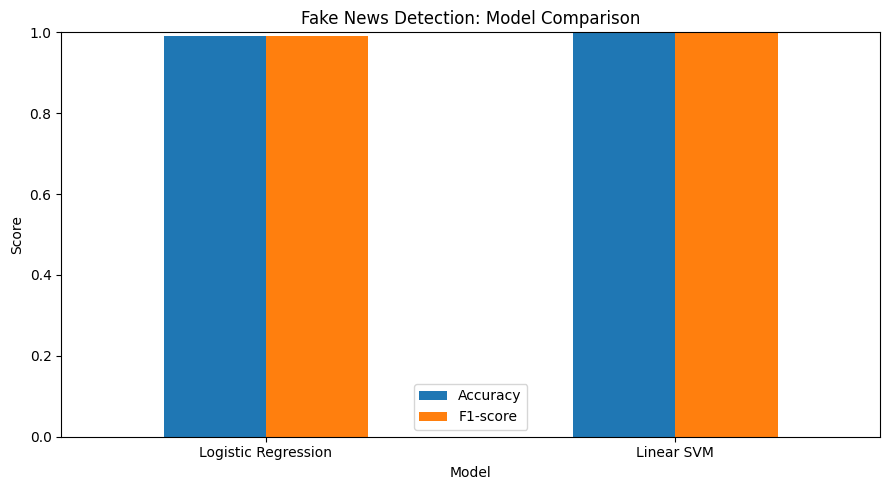

In [35]:

results_df = pd.DataFrame({
    "Model": ["Logistic Regression", "Linear SVM"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_svm)
    ],
    "Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_svm)
    ],
    "Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_svm)
    ],
    "F1-score": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_svm)
    ]
})

display(results_df.round(4))

results_df.set_index("Model")[["Accuracy", "F1-score"]].plot(
    kind="bar",
    figsize=(9, 5),
    ylim=(0, 1),
    rot=0
)

plt.title("Fake News Detection: Model Comparison")
plt.ylabel("Score")
plt.tight_layout()
plt.show()


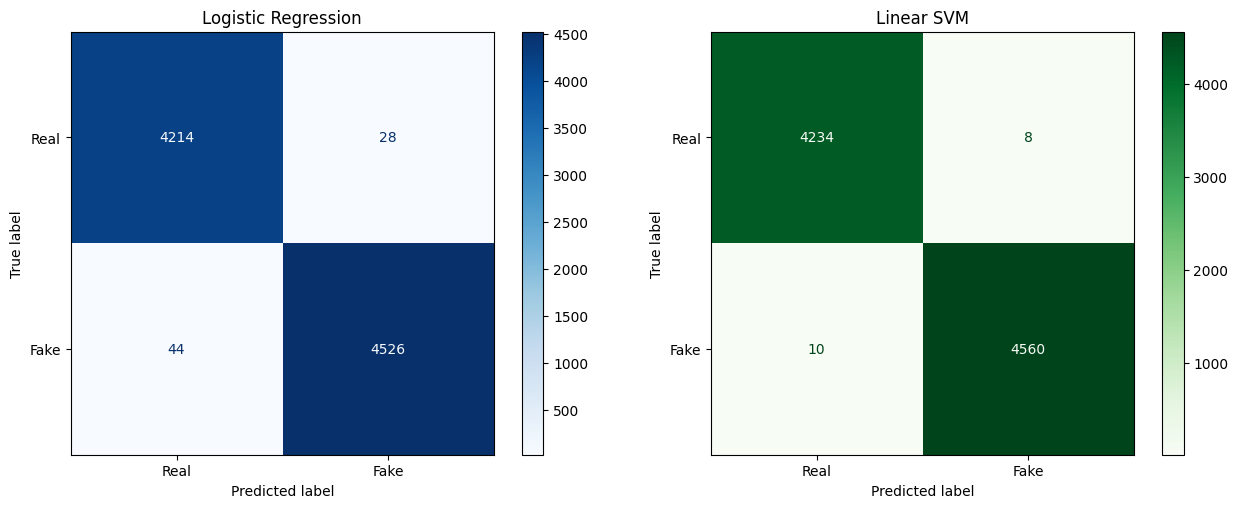

In [36]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_lr,
    display_labels=["Real", "Fake"],
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_svm,
    display_labels=["Real", "Fake"],
    cmap="Greens",
    ax=axes[1]
)
axes[1].set_title("Linear SVM")

plt.tight_layout()
plt.show()


In [37]:

!pip -q install wordcloud


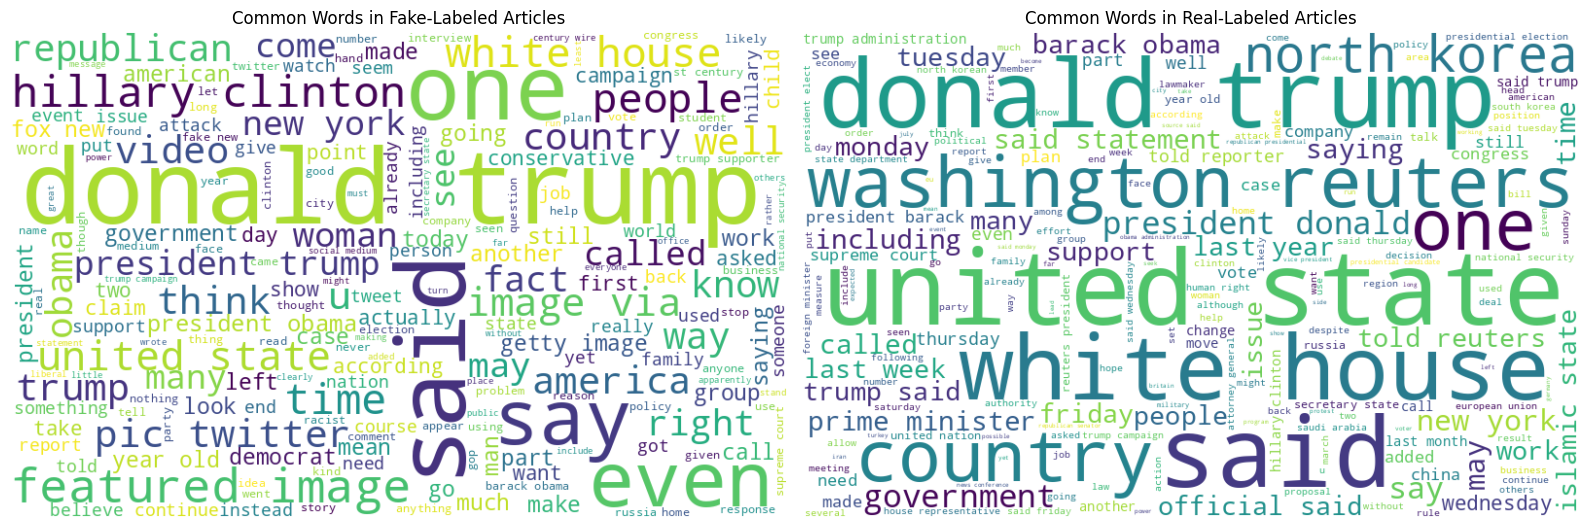

In [38]:

from wordcloud import WordCloud

fake_text = " ".join(
    news_df.loc[news_df["label"] == 1, "clean_content"].astype(str)
)

real_text = " ".join(
    news_df.loc[news_df["label"] == 0, "clean_content"].astype(str)
)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

fake_cloud = WordCloud(
    width=800,
    height=500,
    background_color="white"
).generate(fake_text)

real_cloud = WordCloud(
    width=800,
    height=500,
    background_color="white"
).generate(real_text)

axes[0].imshow(fake_cloud, interpolation="bilinear")
axes[0].set_title("Common Words in Fake-Labeled Articles")
axes[0].axis("off")

axes[1].imshow(real_cloud, interpolation="bilinear")
axes[1].set_title("Common Words in Real-Labeled Articles")
axes[1].axis("off")

plt.tight_layout()
plt.show()


In [39]:

example_news = [
    "The central bank announced a new policy following its regular economic review.",
    "Scientists announced a new research breakthrough after conducting extensive experiments.",
    "A viral post claims that a secret device can cure every disease instantly."
]

# Apply the same preprocessing used for training
clean_examples = [clean_text(text) for text in example_news]

# Apply the already-fitted TF-IDF vectorizer
examples_tfidf = tfidf.transform(clean_examples)

# Predict labels
example_predictions = svm_model.predict(examples_tfidf)

for text, prediction in zip(example_news, example_predictions):
    label = "Fake-labeled" if prediction == 1 else "Real-labeled"
    print("Article:", text)
    print("Model prediction:", label)
    print("-" * 70)


Article: The central bank announced a new policy following its regular economic review.
Model prediction: Fake-labeled
----------------------------------------------------------------------
Article: Scientists announced a new research breakthrough after conducting extensive experiments.
Model prediction: Fake-labeled
----------------------------------------------------------------------
Article: A viral post claims that a secret device can cure every disease instantly.
Model prediction: Fake-labeled
----------------------------------------------------------------------


In [40]:

results_df.to_csv(
    "fake_news_model_comparison_results.csv",
    index=False
)

print("Model comparison results saved!")
display(results_df.round(4))


Model comparison results saved!


,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.9918,0.9939,0.9904,0.9921
1,Linear SVM,0.9980,0.9982,0.9978,0.9980


In [41]:

import joblib

joblib.dump(svm_model, "fake_news_svm_model.pkl")
joblib.dump(tfidf, "fake_news_tfidf_vectorizer.pkl")

print("Model and vectorizer saved!")


Model and vectorizer saved!


In [42]:

files.download("fake_news_svm_model.pkl")
files.download("fake_news_tfidf_vectorizer.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>